In [70]:
import pandas as pd
import matplotlib.pyplot as plt

# Read the table into a Pandas DataFrame
df = pd.read_csv("HarrisPartII.csv")

# Display the shape and some of the fields to make it more sense.
print("Rows and columns:", df.shape)
print(df[["ID", "[Fe/H]", "M_V,t", "B-V"]].head())

Rows and columns: (157, 14)
          ID  [Fe/H]  M_V,t   B-V
0    NGC 104   -0.72  -9.42  0.88
1    NGC 288   -1.32  -6.75  0.65
2    NGC 362   -1.26  -8.43  0.77
3  Whiting 1   -0.70  -2.46   NaN
4   NGC 1261   -1.27  -7.80  0.72


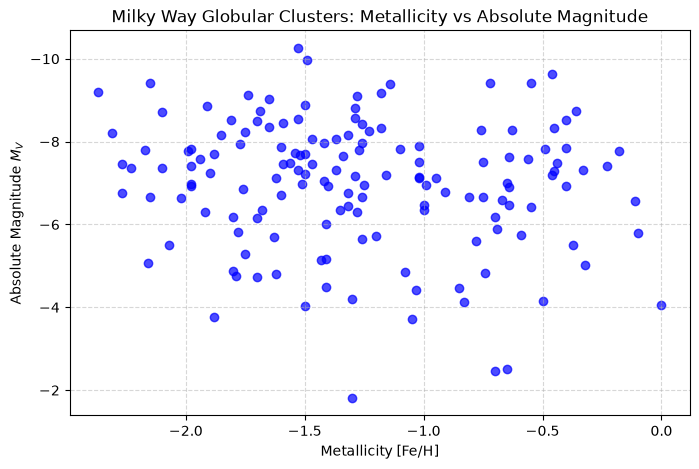

In [71]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(df['[Fe/H]'], df['M_V,t'], color='blue', alpha=0.7)

# In astronomy, brighter magnitudes are more negative, so invert the y-axis
plt.gca().invert_yaxis()

plt.xlabel('Metallicity [Fe/H]')
plt.ylabel('Absolute Magnitude $M_V$')
plt.title('Milky Way Globular Clusters: Metallicity vs Absolute Magnitude')
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

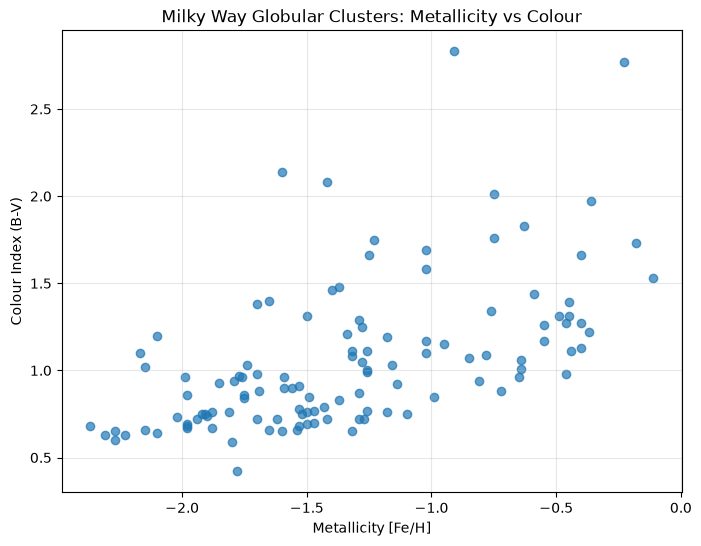

In [72]:

plt.figure(figsize=(8, 6))

plt.scatter(df["[Fe/H]"], df["B-V"], alpha=0.7)

plt.xlabel("Metallicity [Fe/H]")
plt.ylabel("Colour Index (B-V)")
plt.title("Milky Way Globular Clusters: Metallicity vs Colour")
plt.grid(True, alpha=0.3)

plt.show()

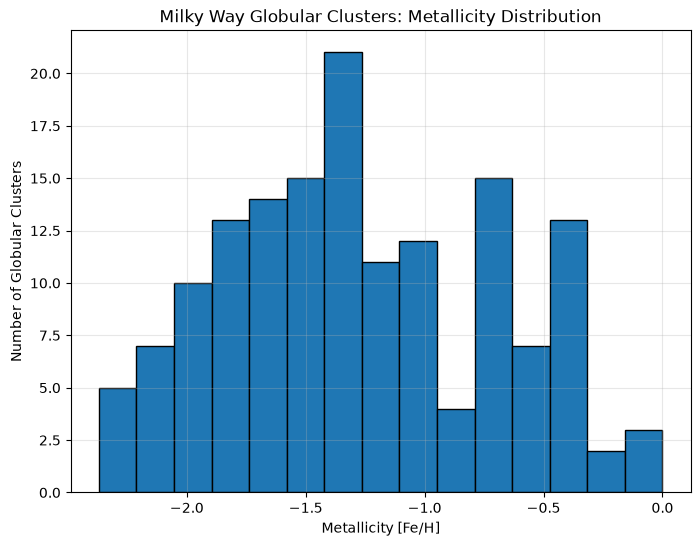

In [73]:

plt.figure(figsize=(8, 6))

plt.hist(df["[Fe/H]"].dropna(), bins=15, edgecolor="black")

plt.xlabel("Metallicity [Fe/H]")
plt.ylabel("Number of Globular Clusters")
plt.title("Milky Way Globular Clusters: Metallicity Distribution")
plt.grid(True, alpha=0.3)

plt.show()

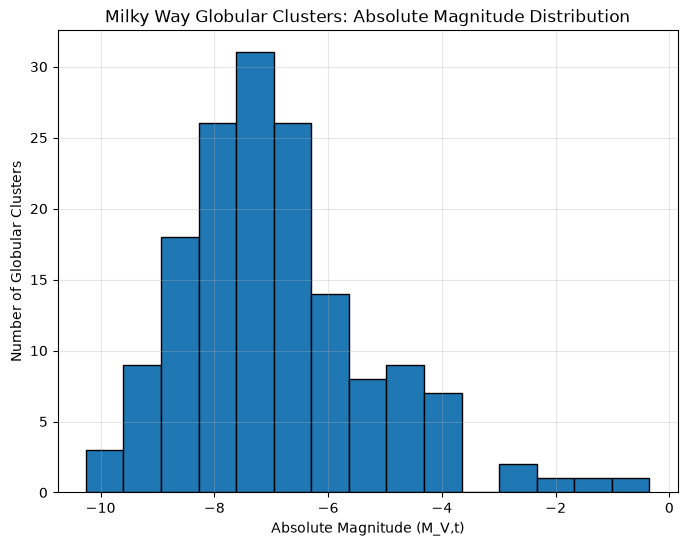

In [74]:

plt.figure(figsize=(8, 6))

plt.hist(df["M_V,t"].dropna(), bins=15, edgecolor="black")

plt.xlabel("Absolute Magnitude (M_V,t)")
plt.ylabel("Number of Globular Clusters")
plt.title("Milky Way Globular Clusters: Absolute Magnitude Distribution")
plt.grid(True, alpha=0.3)

plt.show()

In [75]:
# ok, so we load daniels combined table for the age-metallicity analysis
master = pd.read_csv("../Daniel's Folder/master.csv")

print("Rows and columns: ", master.shape)

print(
    master[["ID", "FeH_VDB", "Age_VDB", "FeH_Krause21", "Age_Krause21"]].head()
)

Rows and columns:  (157, 33)
         ID  FeH_VDB  Age_VDB  FeH_Krause21  Age_Krause21
0  1636-283      NaN      NaN           NaN           NaN
1  2MS-GC01      NaN      NaN           NaN           NaN
2  2MS-GC02      NaN      NaN           NaN           NaN
3      AM 1      NaN      NaN           NaN           NaN
4      AM 4      NaN      NaN           NaN           NaN


the van den Berg clusters:  55
Krause clusters:  61


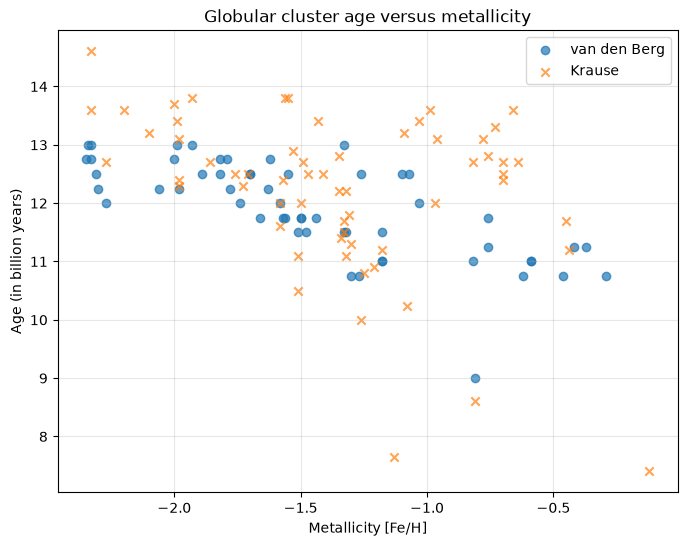

In [76]:
# ok, so now we keep only clusters with both the metallicity and the age from each source otherwise we 
# dont and we just print to see their length and just built a scatter plot.

vdb = master.dropna(subset=["FeH_VDB", "Age_VDB"])
krause = master.dropna(subset=["FeH_Krause21", "Age_Krause21"])

print("the van den Berg clusters: ", len(vdb))
print("Krause clusters: ", len(krause))

plt.figure(figsize=(8,6))

plt.scatter(
    vdb["FeH_VDB"], vdb["Age_VDB"],
    label="van den Berg", alpha=0.7
)

plt.scatter(
    krause["FeH_Krause21"], krause["Age_Krause21"],
    label="Krause", marker="x", alpha=0.7
)

plt.xlabel("Metallicity [Fe/H]")
plt.ylabel("Age (in billion years)")
plt.title("Globular cluster age versus metallicity")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [77]:
# now we copy the van den Berg rows without changig the original table
vdb_table = vdb[["ID", "Age_VDB", "FeH_VDB", "Age_err"]].copy()

# nowe we give the age and metallicity columsn the names that the rule cell expects.
vdb_table = vdb_table.rename(columns={"Age_VDB": "Age", "FeH_VDB": "FeH"})

# now we record where this stuff comes from
vdb_table["source"] = "van den Berg"

# now we copy the krause rows without changing the original table.
krause_table = krause[["ID", "Age_Krause21", "FeH_Krause21"]].copy()

# now we give krause age and metallicity the same name
krause_table = krause_table.rename(columns={"Age_Krause21": "Age", "FeH_Krause21": "FeH"})

# so krause has no age-error column here missing that does not mean zero error.
krause_table["Age_err"] = pd.NA

# now we record where the measureemnts again came from
krause_table["source"] = "Krause"

# now we put both into one table but we don NOT average their values
age_metal_table = pd.concat([vdb_table, krause_table], ignore_index=True)
age_metal_table = age_metal_table[["ID", "source", "Age", "FeH", "Age_err"]]

# check that both sources are present before running rule.
print(age_metal_table.groupby("source").size())

source
Krause          61
van den Berg    55
dtype: int64


In [78]:
# We want to find clusters whose age is unusual compared with clusters of similar metallicity.
# We compare within each data source separately so different measurement methods are not mixed.
# A cluster is only judged if it has enough others to compare with; otherwise we leave it unassessed.
# The limits below are our chosen screening rules, not proof of where a cluster came from.

# these are the rules we set that we will use to construct the flagged list
metallicity_window = 0.25 # how close the other clusters FeH needs to be
minimum_neighbours = 4 # we need at least four other clusters for a comparison
age_cutoff = 2.0 # we kinda only flag if it differs by at least 2 billion years

checks = []

# now we work through each source seperately
# split the table so like Krause and others are only compared Krause. 
for source, sources_rows in age_metal_table.groupby("source"):
    # now we look at one clusters at a time within that source
    for _, cluster in sources_rows.iterrows():

        # now we keep rows that ae not this cluster and have nearby FeH values
        nearby = sources_rows[
            (sources_rows["ID"] != cluster["ID"]) &
            ((sources_rows["FeH"] - cluster["FeH"]).abs() <= metallicity_window)
        ]

        # now we start these as missing; they stay missing if there aren't enough neighbours.
        middle_age = float("nan")
        age_difference = float("nan")

        # do not judge a cluster if it only has less than the min neighbours
        if len(nearby) < minimum_neighbours:
            result = "not enough to compare"
        else:
            # now we find the middle of the nearby clusters
            middle_age = nearby["Age"].median()
            # positive = this cluster is older; negative = it is younger
            age_difference = cluster["Age"] - middle_age

            # now we check whether it differs by at least 2 billion years
            if age_difference >= age_cutoff:
                result = "flagged older"
            elif age_difference <= -age_cutoff:
                result = "flagged younger"
            else:
                result = "not flagged"

        # now we add this clusters details and result to our list
        checks.append({
            "ID": cluster["ID"],
            "source": source,
            "Age": cluster["Age"],
            "FeH": cluster["FeH"],
            "Age_err": cluster["Age_err"],
            "nearby_count": len(nearby),
            "middle_age": middle_age,
            "age_difference": age_difference,
            "result": result
        })

# now we turn this into a pandas table
age_checks = pd.DataFrame(checks)
# now we count how many rows got each result in each source.
print(age_checks.groupby(["source", "result"]).size())

# show the shortlist. the full age_checks table still keeps everyone else.
flagged_age = age_checks[
    age_checks["result"].isin(["flagged older", "flagged younger"])
]

# display it, duh
display(flagged_age)

source        result               
Krause        flagged older             1
              flagged younger           2
              not enough to compare     2
              not flagged              56
van den Berg  flagged younger           1
              not enough to compare     1
              not flagged              53
dtype: int64


,ID,source,Age,FeH,Age_err,nearby_count,middle_age,age_difference,result
2,NGC 1851,Krause,7.64,-1.13,<NA>,19,11.7,-4.06,flagged younger
25,NGC 6171,Krause,13.40,-1.03,<NA>,13,11.2,2.20,flagged older
58,Pal 12,Krause,8.60,-0.81,<NA>,13,12.8,-4.20,flagged younger
114,Pal 12,van den Berg,9.00,-0.81,0.38,7,11.0,-2.00,flagged younger


## Looking for unusual ages

I compare each cluster with other clustes from the same dataset that are within 0.25 of its 'FeH' value. This is cuz we wanna keep the comparison local but also want other clusters to compare our cluster with. I leave the cluster itself out and require at least four others.

Then, I use the middle age of nearby clusters cuz a very old or young value will not really pull it as much as average. I flag a cluster when its age is at least 2 billion years older or younger than the middle age of the nearby clusters. These numbers are choices for making a first shortlist, not known boundaries between different kinds of clusters. If there are fewer than four nearby clusters, I say there is not enough to compare.

## First shortlist 

The rule flagged only four measurements; one as older and three as younger. Three other measurements did not have enough nearby clusters for this comparison. A flag only means that an age stands out under this rule. I lowk still need to check the original values, the age uncertainties where available, and like whether changing the rules changes the shortlist. It does NOT tell me where the cluster is formed.

In [79]:
# The previous cell used one set of limits. Now we use the same age check with several limits
# just to see if the flagged clusters change. The function keeps the method the same each time.
# Only the metallicity window and age cutoff change. A flag that survives several settings
# is less dependent on our exact choices.

# mostly the previous code y'know
def run_age_rule(window, cutoff):
    results = []

    # now we work through each source seperately
    # split the table so like Krause and others are only compared Krause. 
    for source, sources_rows in age_metal_table.groupby("source"):
        # now we look at one clusters at a time within that source
        for _, cluster in sources_rows.iterrows():

            # now we keep rows that ae not this cluster and have nearby FeH values
            nearby = sources_rows[
                (sources_rows["ID"] != cluster["ID"]) &
                ((sources_rows["FeH"] - cluster["FeH"]).abs() <= window)
            ]

            # now we start these as missing; they stay missing if there aren't enough neighbours.
            middle_age = float("nan")
            age_difference = float("nan")

            # do not judge a cluster if it only has less than the min neighbours
            if len(nearby) < minimum_neighbours:
                result = "not enough to compare"
            else:
                # now we find the middle of the nearby clusters
                middle_age = nearby["Age"].median()
                # positive = this cluster is older; negative = it is younger
                age_difference = cluster["Age"] - middle_age

                # now we check whether it differs by at least 2 billion years
                if age_difference >= cutoff:
                    result = "flagged older"
                elif age_difference <= -cutoff:
                    result = "flagged younger"
                else:
                    result = "not flagged"

            # now we add this clusters details and result to our list
            results.append({
                "ID": cluster["ID"],
                "source": source,
                "Age": cluster["Age"],
                "FeH": cluster["FeH"],
                "Age_err": cluster["Age_err"],
                "nearby_count": len(nearby),
                "middle_age": middle_age,
                "age_difference": age_difference,
                "result": result
            })

    return pd.DataFrame(results)

# now we turn this into a pandas table
age_checks = run_age_rule(metallicity_window, age_cutoff)
# now we count how many rows got each result in each source.
print(age_checks.groupby(["source", "result"]).size())

# show the shortlist. the full age_checks table still keeps everyone else.
flagged_age = age_checks[
    age_checks["result"].isin(["flagged older", "flagged younger"])
]

# display it, duh
display(flagged_age)

# different settings we wanna try
setting = [
    ("baseline", 0.25, 2.0),
    ("narrower window", 0.20, 2.0),
    ("wider window", 0.30, 2.0),
    ("lower age cutoff", 0.25, 1.5),
    ("higher age cutoff", 0.25, 2.5),
]

runs = []

for label, window, cutoff in setting:
    this_run = run_age_rule(window=window, cutoff=cutoff)
    this_run["setting"] = label
    runs.append(this_run)

all_runs = pd.concat(runs, ignore_index=True)

# count flagged, unflagged, and unassessable rows in every settig
print(all_runs.groupby(["setting", "result"]).size())

# put each setting in a column for same source and ID
comparison = all_runs.pivot(
    index=["source", "ID"],
    columns="setting",
    values="result"
)

setting_labels = []

for label, windows, cutoff in setting:
    setting_labels.append(label)

comparison = comparison[setting_labels]

#  now show any measurement flagged under at least one setting

flagged_somwewhere = []

for _, row in comparison.iterrows():
    found_flag = False

    for result in row:
        if result.startswith("flagged"):
            found_flag = True
            break

    flagged_somwewhere.append(found_flag)

flagged_somwewhere = pd.Series(
    flagged_somwewhere,
    index=comparison.index
)

display(comparison[flagged_somwewhere])

source        result               
Krause        flagged older             1
              flagged younger           2
              not enough to compare     2
              not flagged              56
van den Berg  flagged younger           1
              not enough to compare     1
              not flagged              53
dtype: int64


,ID,source,Age,FeH,Age_err,nearby_count,middle_age,age_difference,result
2,NGC 1851,Krause,7.64,-1.13,<NA>,19,11.7,-4.06,flagged younger
25,NGC 6171,Krause,13.40,-1.03,<NA>,13,11.2,2.20,flagged older
58,Pal 12,Krause,8.60,-0.81,<NA>,13,12.8,-4.20,flagged younger
114,Pal 12,van den Berg,9.00,-0.81,0.38,7,11.0,-2.00,flagged younger


setting            result               
baseline           flagged older              1
                   flagged younger            3
                   not enough to compare      3
                   not flagged              109
higher age cutoff  flagged younger            2
                   not enough to compare      3
                   not flagged              111
lower age cutoff   flagged older              5
                   flagged younger            5
                   not enough to compare      3
                   not flagged              103
narrower window    flagged older              1
                   flagged younger            3
                   not enough to compare      7
                   not flagged              105
wider window       flagged younger            4
                   not enough to compare      1
                   not flagged              111
dtype: int64


setting                       baseline  narrower window     wider window  \
source       ID                                                            
Krause       NGC 1851  flagged younger  flagged younger  flagged younger   
             NGC 362       not flagged      not flagged  flagged younger   
             NGC 6144      not flagged      not flagged      not flagged   
             NGC 6171    flagged older      not flagged      not flagged   
             NGC 6218      not flagged      not flagged      not flagged   
             NGC 6535      not flagged      not flagged      not flagged   
             NGC 6717      not flagged    flagged older      not flagged   
             NGC 6752      not flagged      not flagged      not flagged   
             Pal 12    flagged younger  flagged younger  flagged younger   
van den Berg Pal 12    flagged younger  flagged younger  flagged younger   

setting               lower age cutoff higher age cutoff  
source       ID                                           
Krause       NGC 1851  flagged younger   flagged younger  
             NGC 362   flagged younger       not flagged  
             NGC 6144    flagged older       not flagged  
             NGC 6171    flagged older       not flagged  
             NGC 6218    flagged older       not flagged  
             NGC 6535  flagged younger       not flagged  
             NGC 6717    flagged older       not flagged  
             NGC 6752    flagged older       not flagged  
             Pal 12    flagged younger   flagged younger  
van den Berg Pal 12    flagged younger       not flagged

In [80]:
# Check the three clusters flagged by the baseline rule.
ids_to_check = ["NGC 1851", "NGC 6171", "Pal 12"]

# Show both sources' measurements for each cluster.
source_check = age_metal_table[
    age_metal_table["ID"].isin(ids_to_check)
].sort_values(["ID", "source"])

display(source_check)

,ID,source,Age,FeH,Age_err
57,NGC 1851,Krause,7.64,-1.13,<NA>
3,NGC 1851,van den Berg,11.00,-1.18,0.25
80,NGC 6171,Krause,13.40,-1.03,<NA>
22,NGC 6171,van den Berg,12.00,-1.03,0.75
113,Pal 12,Krause,8.60,-0.81,<NA>
53,Pal 12,van den Berg,9.00,-0.81,0.38


## Checking the age flags

I repeated the age comparison with slightly different metallicity ranges and slightly different age-difference limits. This lets us check whether a cluster stands out most of the time or only with one specific set of settings.

In the Krause data, NGC 1851 and Pal 12 were flagged as, like, younger under all five settings tested. NGC 6171 was flagged as older under only some of the settings, so its result varies a bit more. In the van den Berg data, Pal 12 was flagged as younger under four of the five settings.

I also compared clusters that appeared in both datasets. Both give Pal 12 a similar young age, which makes the result more convincing. They disagree more about the age of NGC 1851, so I will keep it as a candidate to investigate, not remove it from the results. Krause does not provide an age error in this table, so the thing is, we can't exactly know which age estimate is more reliable from these tables alone.

The reason we did this was to check whether the age results are stronger or need more caution. An unusual age does not really establish where a cluster formed. We need to consider that alongside the motion data in the Harris parts.

In [81]:
# now we save every cluster's age-check result, not just the flagged ones
# we keep the source and measurements so the combined notebook can tell
# checked but not flagged apart from not enough to compare
# we leave out the extra row number column cuz it doesn't help us here

age_out = age_checks[["ID", "source", "Age", "FeH", "Age_err", "result"]].copy()

age_out.to_csv("age_checked.csv", index=False)

print("Age results saved:", len(age_out))

Age results saved: 116
